# Cortical Geometry Estimation from EEG

Estimate cortical folding (sulcal depth) from EEG data alone, without individual MRI.
Compare supervised (oracle, leaks ground truth) vs unsupervised (fully data-driven).

**Pipeline:**
1. Estimate cortical depth from accumulated EEG source power on a sphere model
2. Build an estimated forward model at predicted positions
3. Simulate test data on the true brain, invert with the estimated forward model
4. Compare: ground truth sources on true brain vs estimated sources on estimated brain

In [1]:
import mne
import numpy as np
from IPython.display import display, Image

from invert import Solver
from invert.forward import create_forward_model
from invert.simulate import SimulationConfig, SimulationGenerator
from invert.cortical_folding import CorticalFoldingEstimator

## 1. Estimate Cortical Geometry

Fit both methods on the same true forward model (fsaverage).

In [2]:
fwd_true = create_forward_model('ico3', fixed_ori=True, verbose=0)
print(f'True brain: {fwd_true["sol"]["data"].shape[1]} dipoles')

True brain: 1284 dipoles


In [3]:
# Unsupervised: PCA on EEG-derived features + leadfield consistency
# No ground truth depth labels used.
est_unsup = CorticalFoldingEstimator()
est_unsup.fit(fwd_true, method='unsupervised', n_samples=5000)

Building sphere model...
  1284 dipoles, sphere radius=55.4mm
Estimating depth (method=unsupervised, 5000 samples)...
Building eLORETA inverse operator...
Simulating and inverting 5000 EEG samples...
  500/5000 samples
  1000/5000 samples
  1500/5000 samples
  2000/5000 samples
  2500/5000 samples
  3000/5000 samples
  3500/5000 samples
  4000/5000 samples
  4500/5000 samples
  5000/5000 samples
Extracting multi-scale features...
Computing leadfield consistency at multiple radii...
  offset=-25.0mm ok
  offset=-22.5mm ok
  offset=-20.0mm ok
  offset=-17.5mm ok
  offset=-15.0mm ok
  offset=-12.5mm ok
  offset=-10.0mm ok
  offset=-7.5mm ok
  offset=-5.0mm ok
  offset=-2.5mm ok
  offset=+0.0mm ok
  offset=+2.5mm ok
PCA depth estimation (26 features, PC1-4)...
Estimated depth range: [-40.2, 12.2] mm
Estimated depth std: 8.0 mm
Correlation with true depth: rho=0.454 (for reference only)
Building estimated forward model...
  1284 dipoles


In [4]:
# Supervised: SH-regularized regression against true depth (oracle).
# Leaks ground truth — included for comparison only.
est_sup = CorticalFoldingEstimator()
est_sup.fit(fwd_true, method='supervised', n_samples=5000)

Building sphere model...
  1284 dipoles, sphere radius=55.4mm
Estimating depth (method=supervised, 5000 samples)...
Building eLORETA inverse operator...
Simulating and inverting 5000 EEG samples...
  500/5000 samples
  1000/5000 samples
  1500/5000 samples
  2000/5000 samples
  2500/5000 samples
  3000/5000 samples
  3500/5000 samples
  4000/5000 samples
  4500/5000 samples
  5000/5000 samples
  22 features extracted
SH regression (l<=5)...
Prediction: rho=0.517, R2=0.278, MAE=9.6mm
Oracle (true depth at l<=5): rho=0.529
Signal recovered: 98% of oracle
Building estimated forward model...
  1284 dipoles


In [5]:
# Compare depth estimation quality
m_unsup = est_unsup.evaluate()
m_sup = est_sup.evaluate()

print(f'{"Method":<16s} {"rho":>6s} {"MAE":>8s} {"Range":>20s}')
print('-' * 55)
print(f'{"Unsupervised":<16s} {m_unsup["rho"]:6.3f} {m_unsup["mae"]:7.1f}mm '
      f'[{m_unsup["pred_range"][0]:+.0f}, {m_unsup["pred_range"][1]:+.0f}]mm')
print(f'{"Supervised":<16s} {m_sup["rho"]:6.3f} {m_sup["mae"]:7.1f}mm '
      f'[{m_sup["pred_range"][0]:+.0f}, {m_sup["pred_range"][1]:+.0f}]mm')
print(f'{"True range":<16s} {"":>6s} {"":>8s} '
      f'[{m_unsup["true_range"][0]:+.0f}, {m_unsup["true_range"][1]:+.0f}]mm')

Method              rho      MAE                Range
-------------------------------------------------------
Unsupervised      0.454    10.3mm [-40, +12]mm
Supervised        0.517     9.6mm [-43, +15]mm
True range                       [-53, +34]mm


## 2. Create Estimated Brain Surfaces

Build FreeSurfer subject directories so we can use `stc.plot()` on each estimated geometry.

In [6]:
subj_unsup = est_unsup.create_subject('brain_unsupervised')
subj_sup = est_sup.create_subject('brain_supervised')
print(f'Created subjects: {subj_unsup}, {subj_sup}')

Overwriting existing file.
Overwriting existing file.
Overwriting existing file.
Overwriting existing file.
Created subjects: brain_unsupervised, brain_supervised


## 3. Simulate Test Data

Generate EEG from 2 sparse patch sources on the true brain.

In [7]:
test_config = SimulationConfig(
    batch_size=1, n_sources=2, n_timepoints=200,
    snr_range=(10, 10), verbose=0, random_seed=7,
)
test_batch = next(SimulationGenerator(fwd_true, test_config).generate())

info_mne = mne.create_info(
    ch_names=fwd_true['info']['ch_names'], sfreq=250., ch_types='eeg',
)
evoked_test = mne.EvokedArray(test_batch.x[0], info_mne, tmin=0)

# Ground truth STC
verts = [fwd_true['src'][h]['vertno'] for h in range(2)]
stc_true = mne.SourceEstimate(
    test_batch.y[0], verts, tmin=0, tstep=1/250., subject='fsaverage',
)
peak_time = stc_true.times[np.argmax(np.max(np.abs(stc_true.data), axis=0))]

print(f'{test_batch.info.iloc[0]["n_sources"]} sources, '
      f'SNR={test_batch.info.iloc[0]["snr"]:.0f}dB, peak at {peak_time:.3f}s')

2 sources, SNR=10dB, peak at 0.204s


## 4. Source Estimation & Visualization

Invert the test EEG with each estimated forward model.
Ground truth plotted on fsaverage, estimates on their respective estimated brains.

In [8]:
solver_name = 'eloreta'

# Invert with unsupervised model
s1 = Solver(solver_name)
s1.make_inverse_operator(est_unsup.forward, evoked_test, alpha='auto', verbose=0)
stc_unsup = s1.apply_inverse_operator(evoked_test)
stc_unsup.subject = subj_unsup

# Invert with supervised model
s2 = Solver(solver_name)
s2.make_inverse_operator(est_sup.forward, evoked_test, alpha='auto', verbose=0)
stc_sup = s2.apply_inverse_operator(evoked_test)
stc_sup.subject = subj_sup

print('Inverse solutions computed.')

Inverse solutions computed.


Ground truth (true brain):


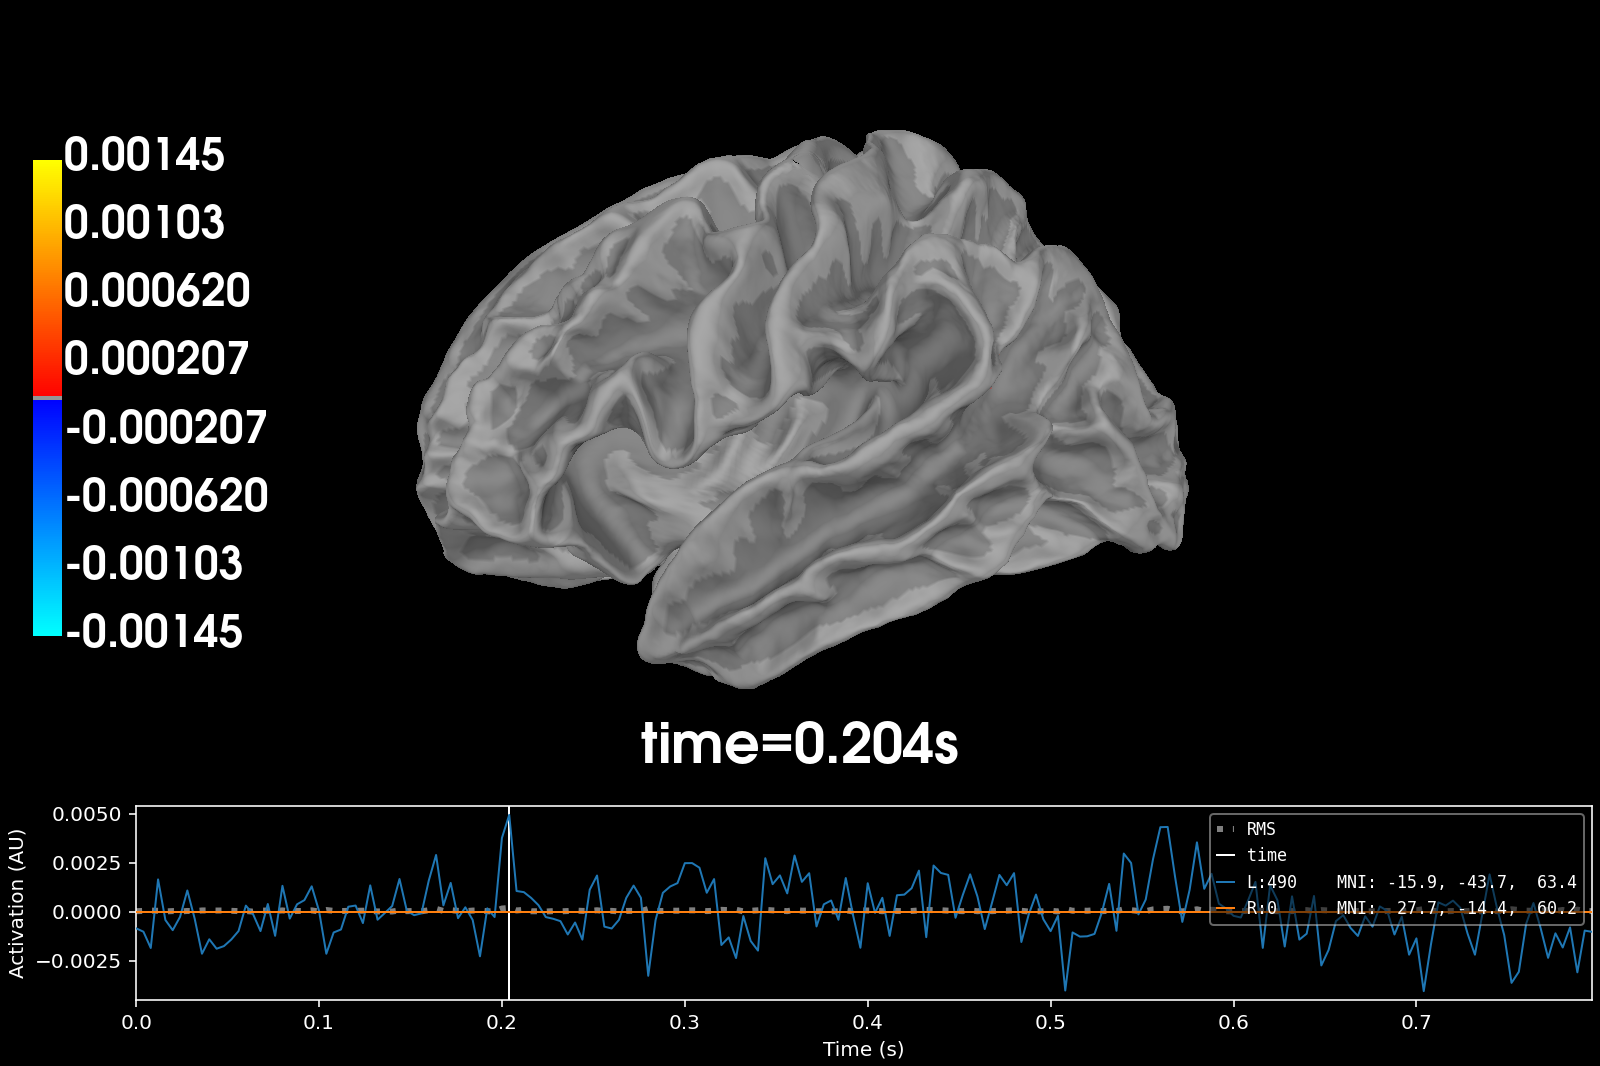


eloreta — unsupervised estimated brain (rho=0.454):


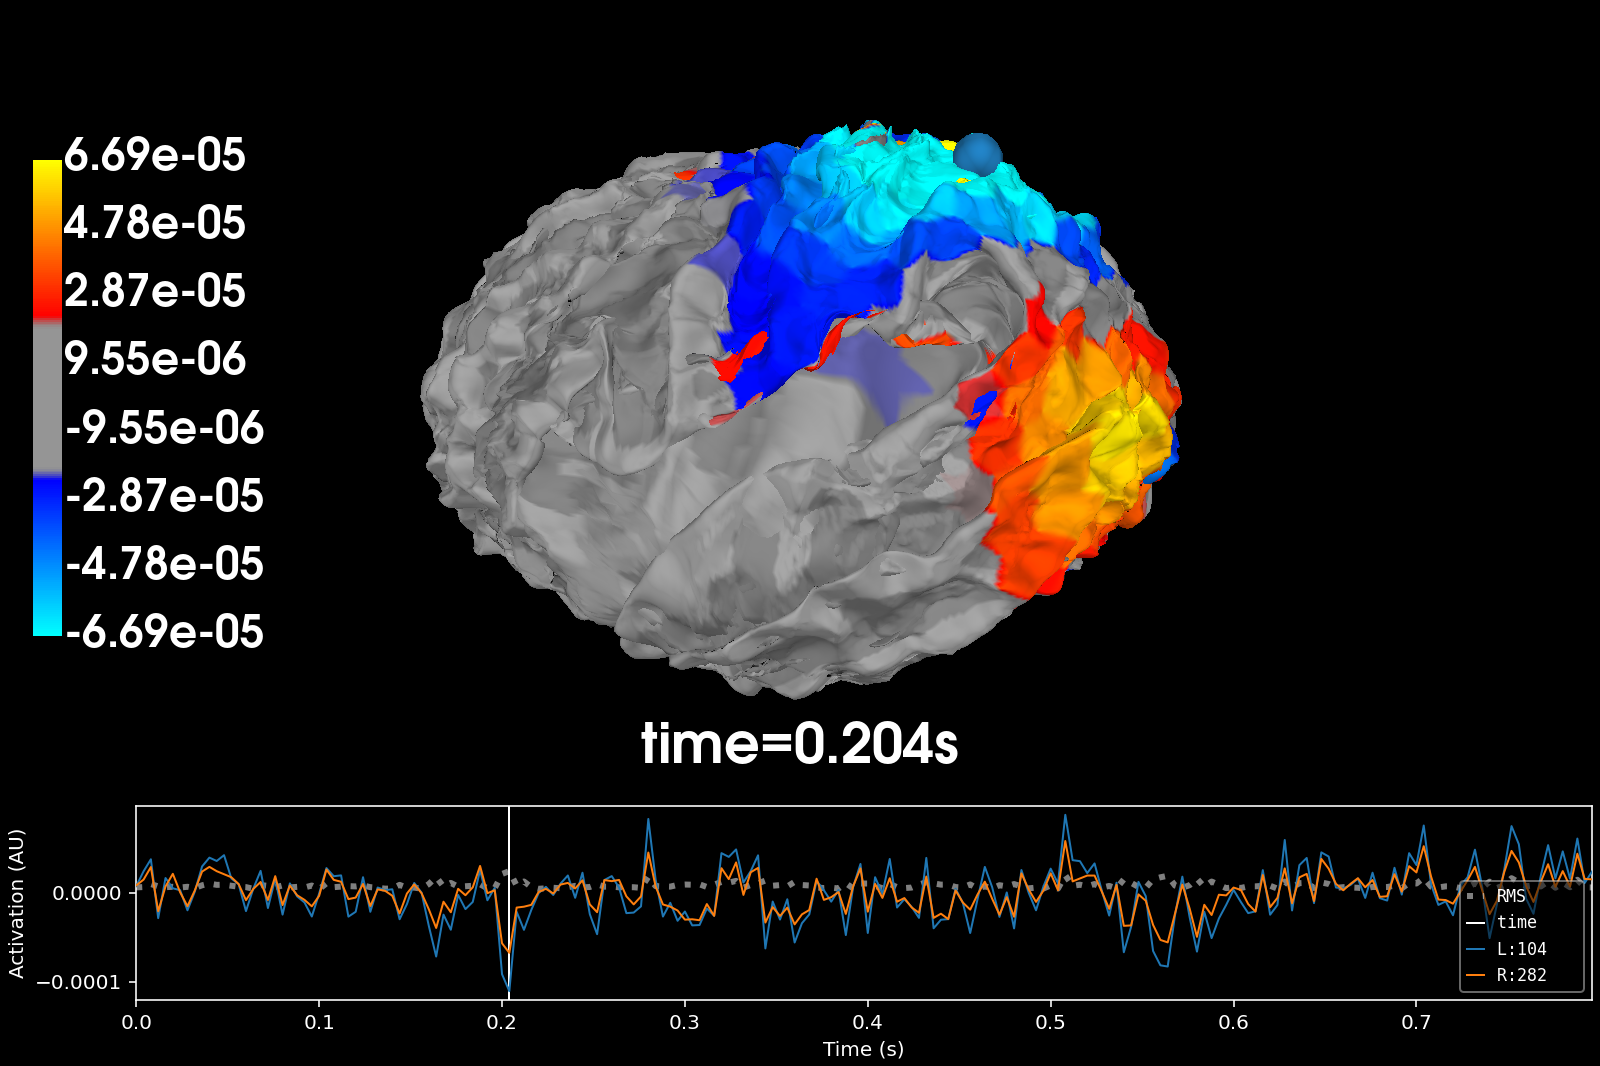


eloreta — supervised estimated brain (rho=0.517):


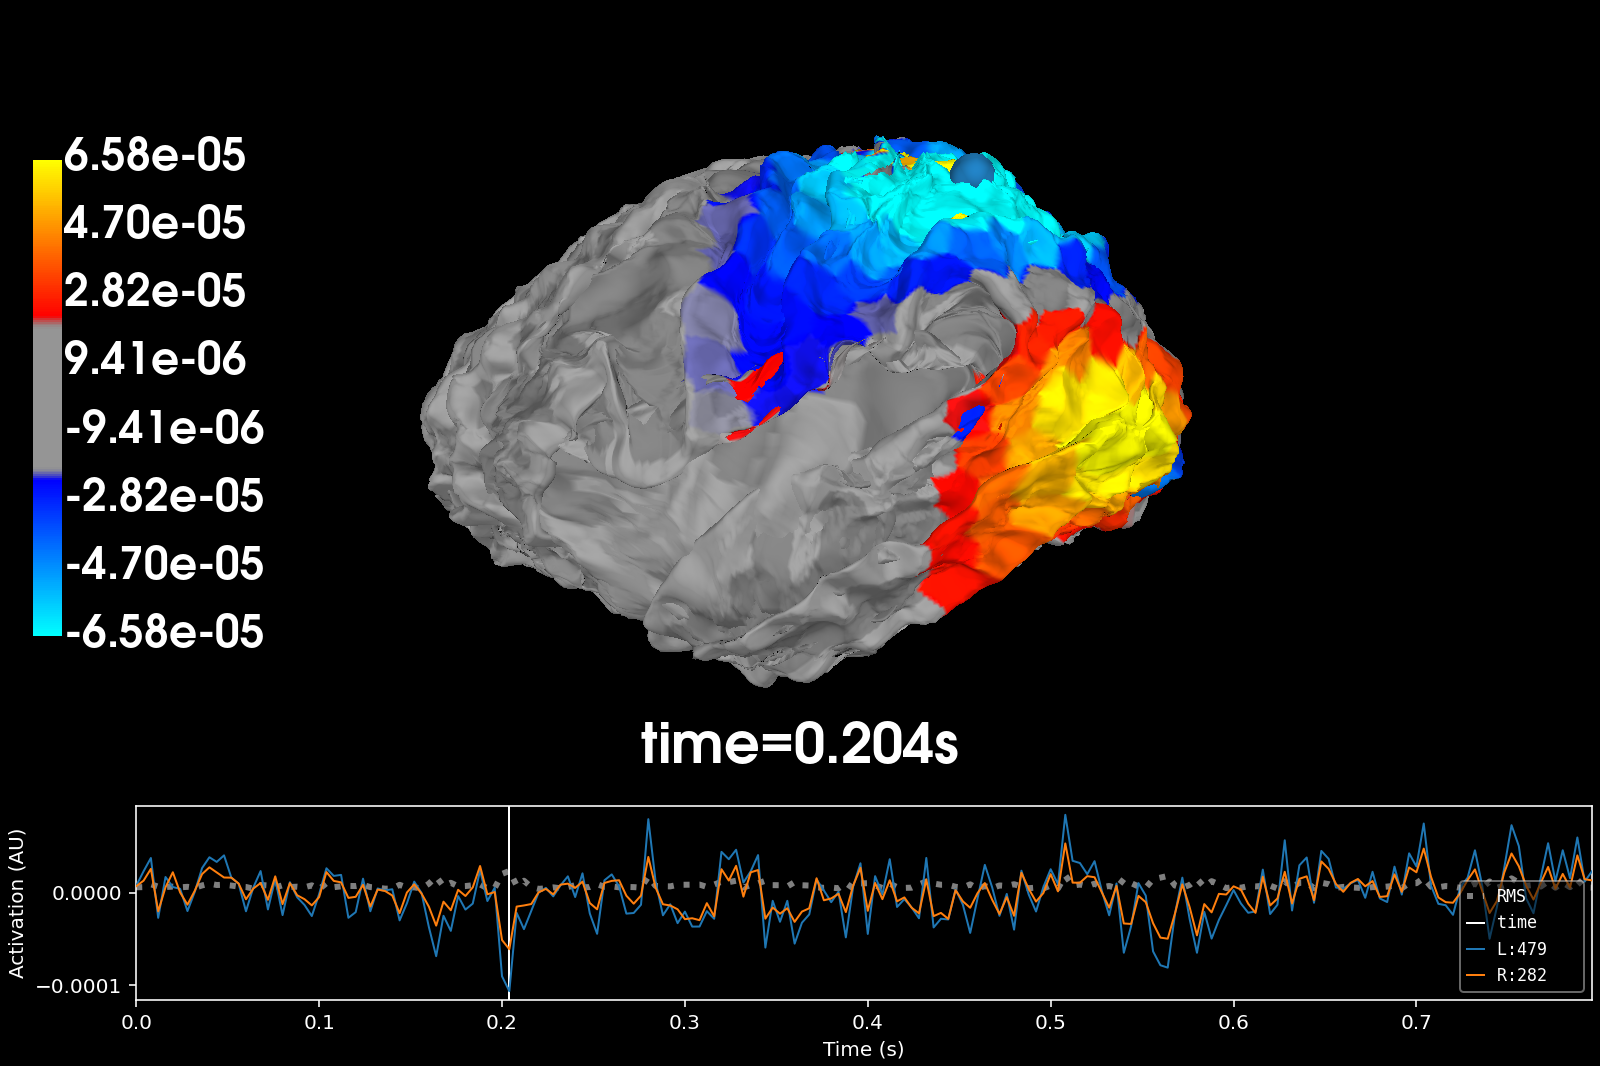

In [9]:
plot_kw = dict(initial_time=peak_time)

print('Ground truth (true brain):')
display(Image(filename=est_unsup.plot_stc(
    stc_true, subject='fsaverage', title='Ground Truth', **plot_kw)))

print(f'\n{solver_name} — unsupervised estimated brain (rho={m_unsup["rho"]:.3f}):')
display(Image(filename=est_unsup.plot_stc(
    stc_unsup, subject=subj_unsup,
    title=f'{solver_name} (unsupervised, rho={m_unsup["rho"]:.3f})', **plot_kw)))

print(f'\n{solver_name} — supervised estimated brain (rho={m_sup["rho"]:.3f}):')
display(Image(filename=est_sup.plot_stc(
    stc_sup, subject=subj_sup,
    title=f'{solver_name} (supervised, rho={m_sup["rho"]:.3f})', **plot_kw)))

## 5. Try Other Solvers

Swap the solver to see how different inverse methods perform on the estimated geometry.

mne:


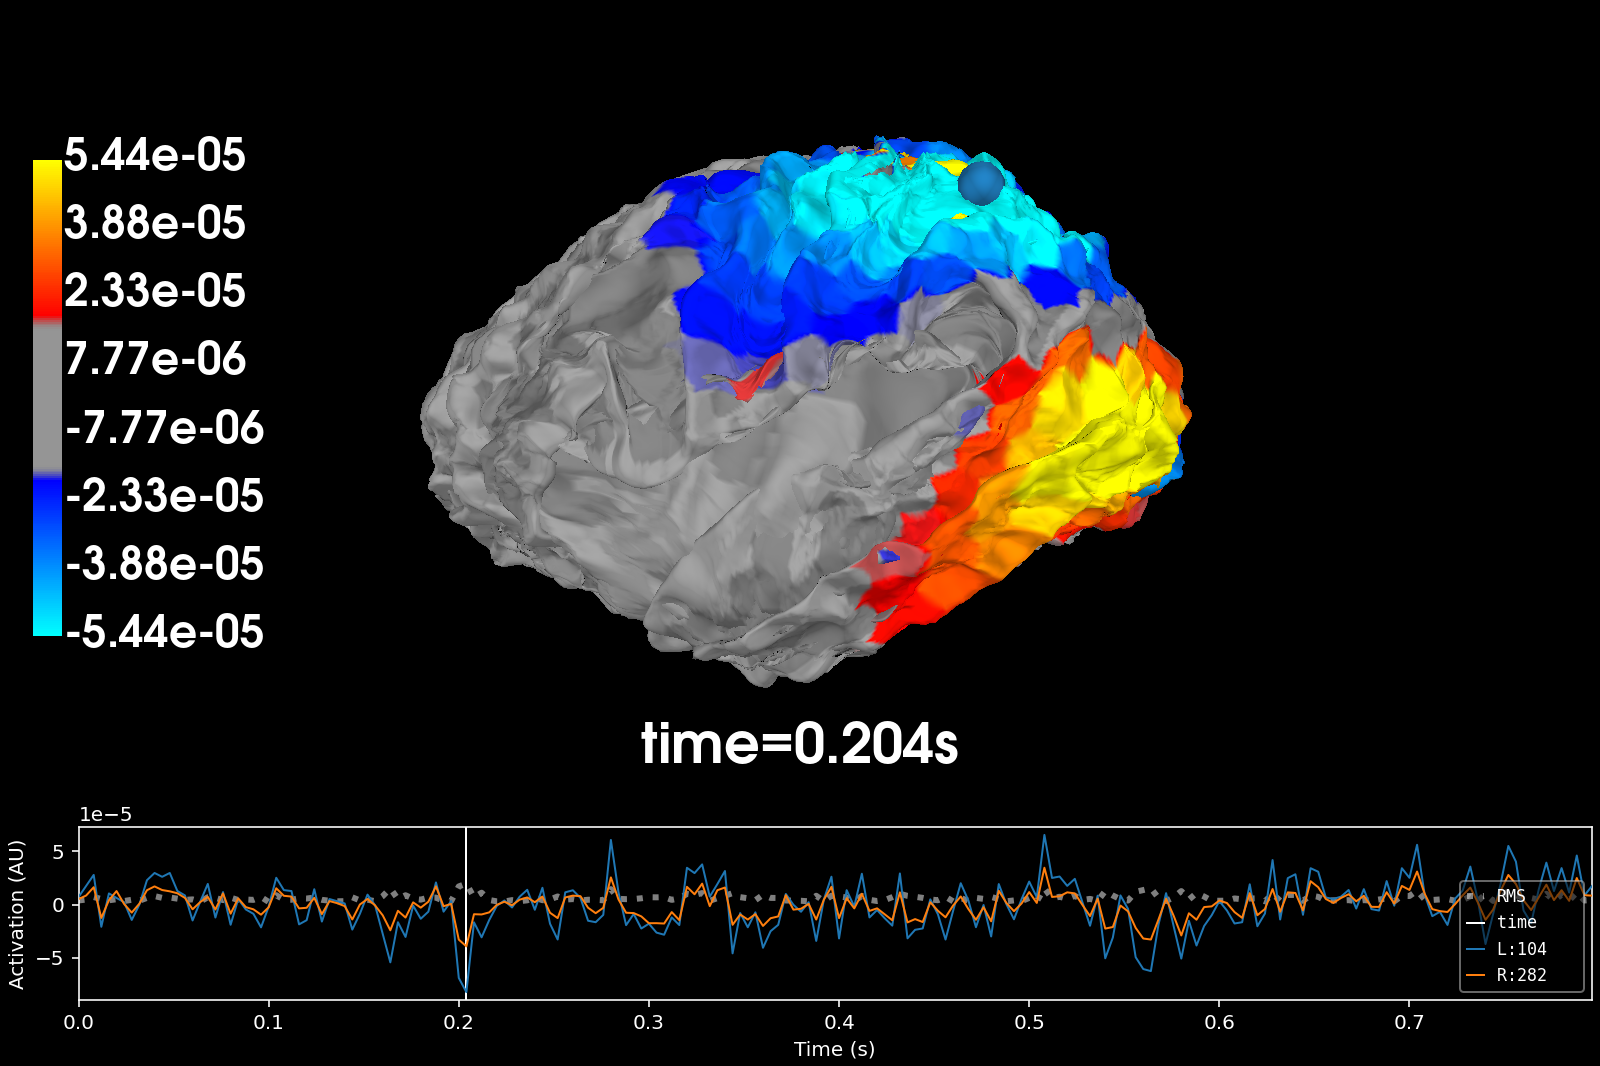

eloreta:


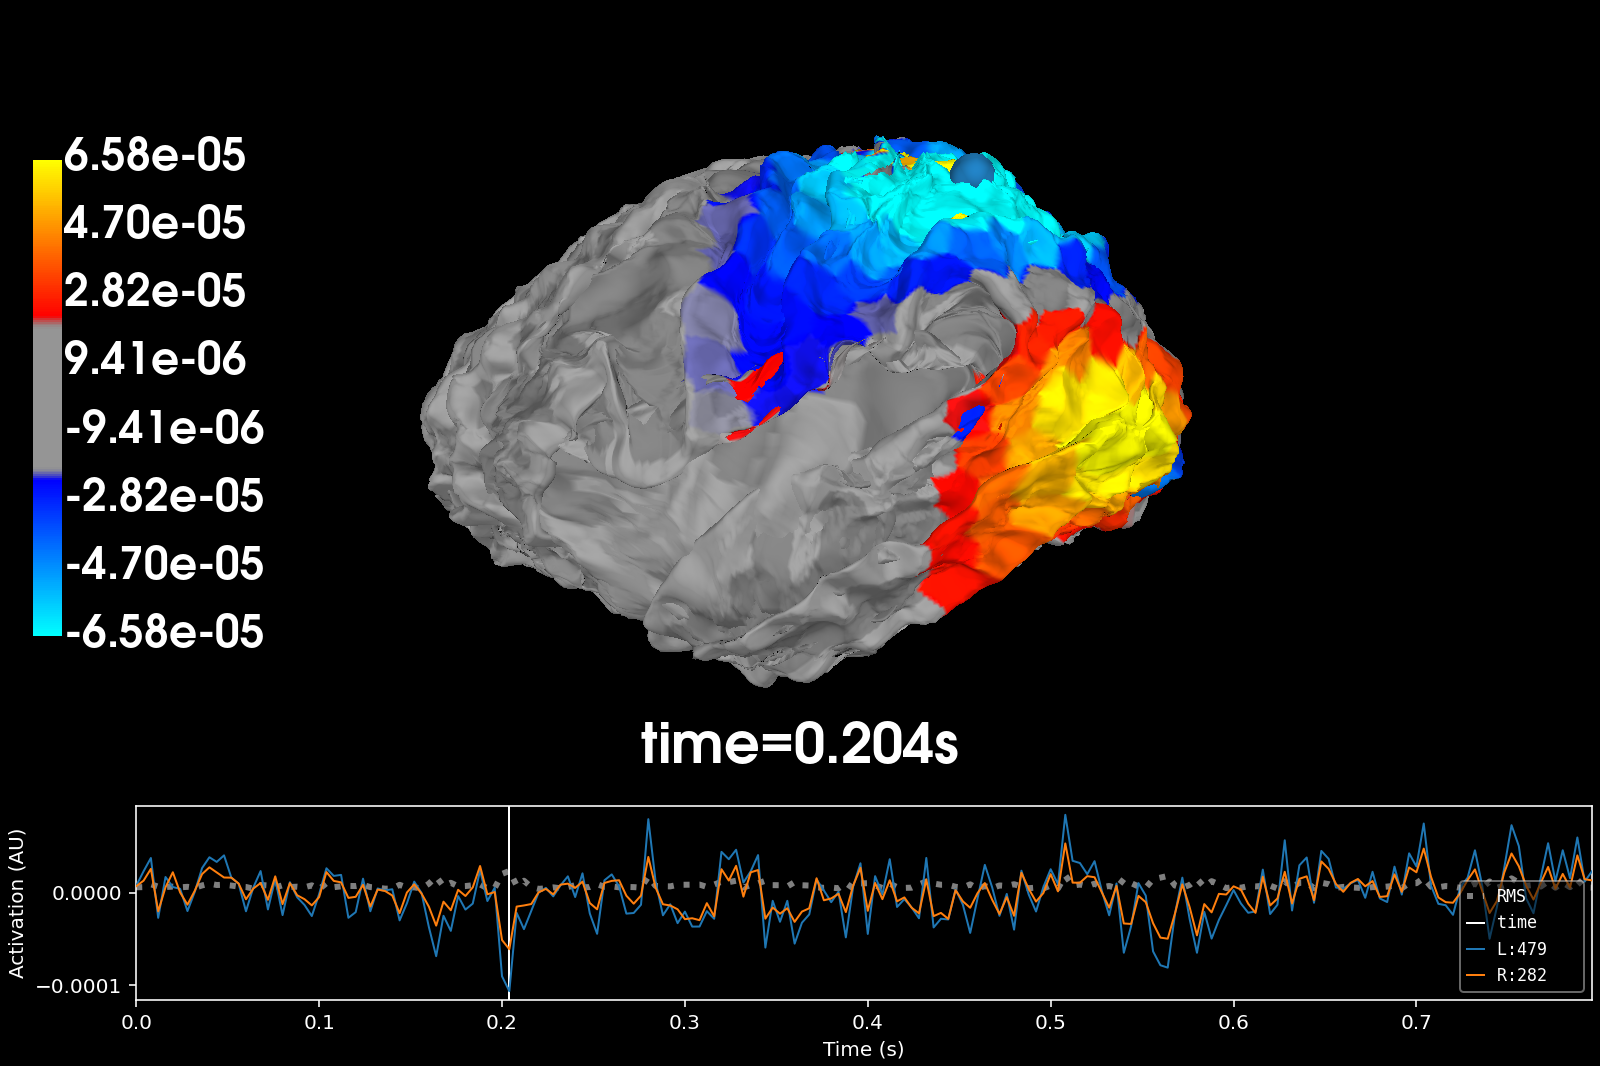

subspace-sbl:


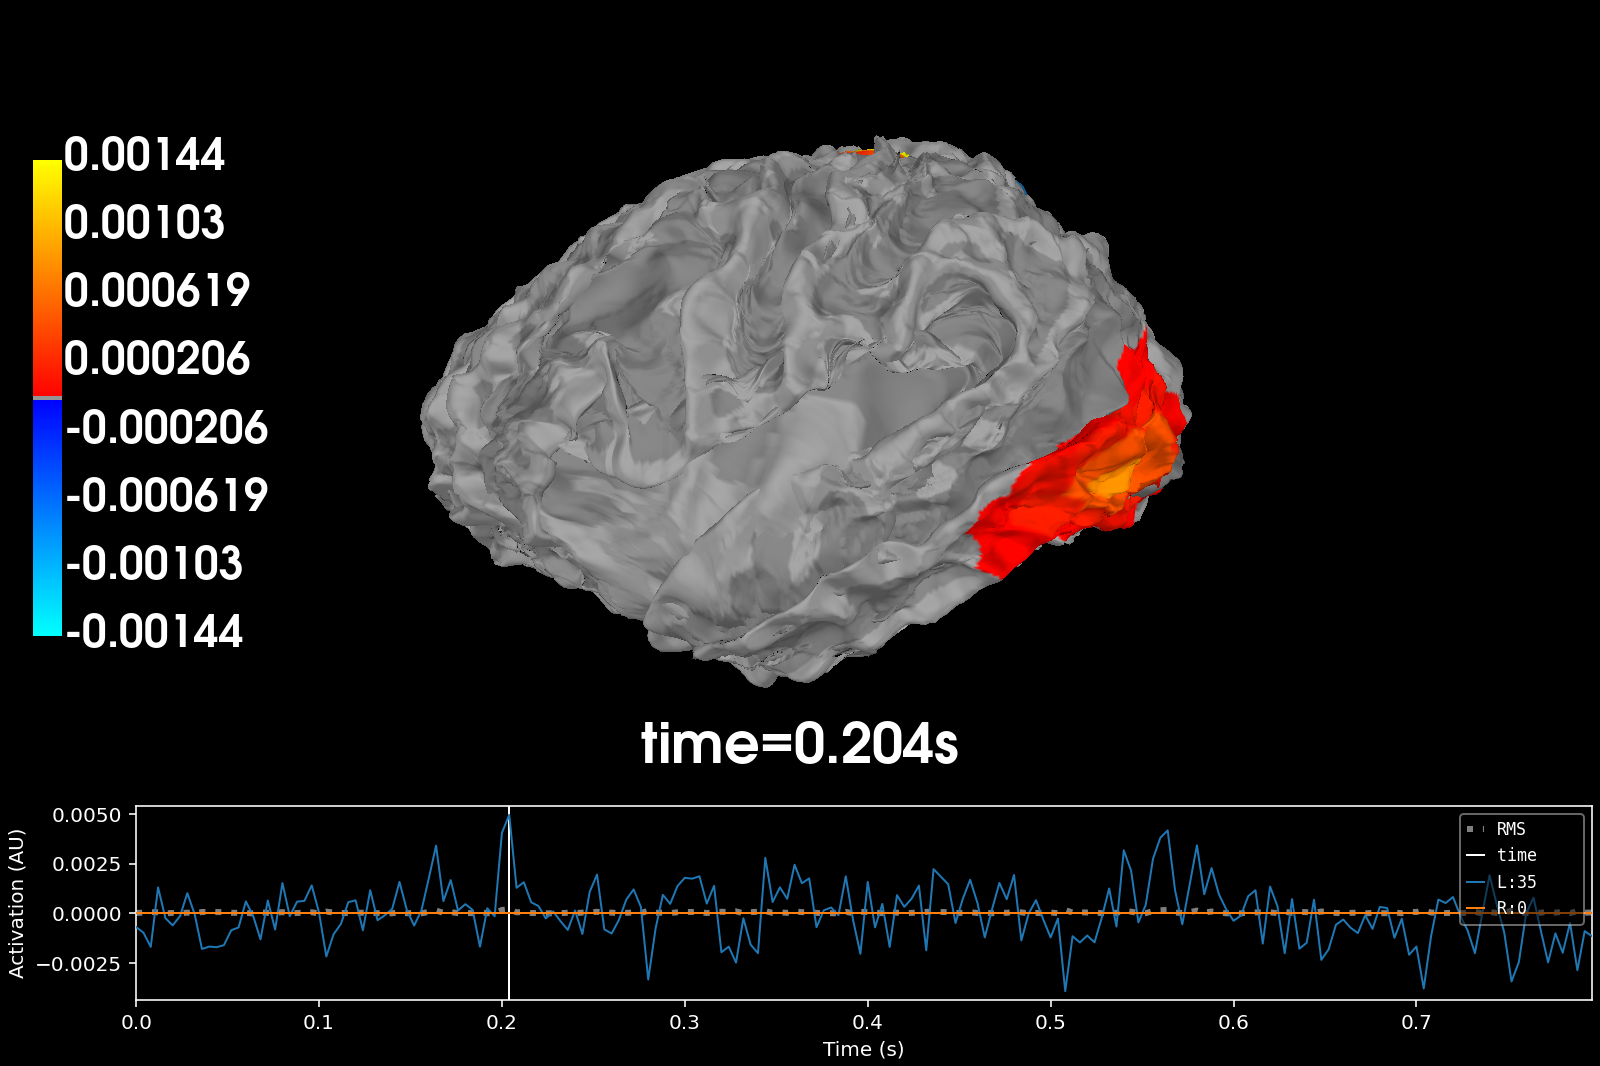

In [14]:
for sname in ['mne', 'eloreta', "subspace-sbl"]:
    s = Solver(sname)
    s.make_inverse_operator(est_sup.forward, evoked_test, alpha='auto', verbose=0)
    stc = s.apply_inverse_operator(evoked_test)
    stc.subject = subj_sup

    print(f'{sname}:')
    display(Image(filename=est_sup.plot_stc(
        stc, subject=subj_sup, title=sname, **plot_kw)))